# ReDream Safety Layer — Evaluation

**Master's Thesis: Ramon Zacharias**  
**Date:** 2026-04-14  
**Model:** Mistral Small 3.2 24B (Scaleway)  

This notebook contains the full evaluation pipeline for the ReDream neuro-symbolic safety layer:

1. **Test Set Evaluation** — Primary metrics on 230 held-out cases (6 nightmare themes)
2. **Boundary Case Analysis** — 36 ambiguous cases evaluated against human annotations
3. **S1 vs S2 Comparison** — Direct classification vs Chain-of-Thought on the dev set
4. **Uncertainty Quantification** — 2×2 analysis: logprobs vs semantic consistency × S1 vs S2

### Data Sources

All CSVs were generated by `experiments/run_benchmark.py` and `experiments/run_consistency_errors.py`.  
To regenerate from scratch:
```bash
uv run python experiments/run_benchmark.py --dataset data/benchmarks/dev_dataset.json --classifier s1   # → benchmark_results.csv
uv run python experiments/run_benchmark.py --dataset data/benchmarks/dev_dataset.json --classifier s2   # → benchmark_results_s2.csv
uv run python experiments/run_benchmark.py --dataset data/benchmarks/test_dataset.json --classifier s1  # → test_benchmark_results.csv
uv run python experiments/run_consistency_errors.py                                                     # → consistency_errors_*.csv
```

In [1]:
import pandas as pd
import numpy as np
import json
from pathlib import Path
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

DATA = Path("../data/benchmarks")

# --- Load all data sources ---
# Dev set (S1 and S2 baselines)
dev_s1 = pd.read_csv(DATA / "benchmark_results.csv")
dev_s2 = pd.read_csv(DATA / "benchmark_results_s2.csv")

# Test set
test_df = pd.read_csv(DATA / "test_benchmark_results.csv")

# Datasets (for test type filtering)
with open(DATA / "test_dataset.json") as f:
    test_dataset = json.load(f)
with open(DATA / "dev_dataset.json") as f:
    dev_dataset = json.load(f)

# Annotation log (human labels)
with open(DATA / "test_annotation_log.json") as f:
    annotations = json.load(f)

# Semantic consistency results (use the fixed run with 25 S2 correct samples)
consistency_csv = sorted(DATA.glob("consistency_errors_*.csv"))[-1]  # latest
consistency_df = pd.read_csv(consistency_csv)

print(f"Dev S1: {len(dev_s1)} cases")
print(f"Dev S2: {len(dev_s2)} cases")
print(f"Test:   {len(test_df)} cases")
print(f"Consistency: {len(consistency_df)} cases (from {consistency_csv.name})")

Dev S1: 480 cases
Dev S2: 480 cases
Test:   315 cases
Consistency: 99 cases (from consistency_errors_20260414_151034.csv)


In [2]:
# --- Build test type lookup from dataset JSON ---
# Maps (user_input[:100]) -> test_type, boundary info
test_type_lookup = {}
for suite in test_dataset:
    for t in suite["tests"]:
        key = t["input"][:100].strip()
        test_type_lookup[key] = {
            "test_type": t.get("test_type", "clean"),
            "boundary": t.get("boundary"),
            "nodeA": t.get("nodeA"),
            "nodeB": t.get("nodeB"),
        }

# Tag each test result row with its test_type
test_df["test_type"] = test_df["user_input"].apply(
    lambda x: test_type_lookup.get(x[:100].strip(), {}).get("test_type", "clean")
)

# Define subsets
BURIED_ALIVE_ID = 3
test_buried = test_df[test_df["suite_id"] == BURIED_ALIVE_ID]
test_valid = test_df[test_df["suite_id"] != BURIED_ALIVE_ID]
test_boundary = test_valid[test_valid["test_type"] == "boundary"]
test_primary = test_valid[
    (test_valid["test_type"].isin(["clean", "multipart"]))
    & (test_valid["gt_safe"].notna())
    & (test_valid["gt_node"].notna())
]

print(f"Buried alive (excluded): {len(test_buried)}")
print(f"Boundary (separate):     {len(test_boundary)}")
print(f"Primary evaluation set:  {len(test_primary)}")
print(f"  Safe:   {(test_primary['gt_safe'] == True).sum()}")
print(f"  Unsafe: {(test_primary['gt_safe'] == False).sum()}")

Buried alive (excluded): 48
Boundary (separate):     36
Primary evaluation set:  231
  Safe:   141
  Unsafe: 90


In [3]:
# --- Helper functions ---

def compute_safety_metrics(df):
    """Compute safety metrics from a benchmark DataFrame."""
    # Filter to rows with ground truth
    labeled = df[df["gt_safe"].notna() & df["gt_node"].notna()].copy()
    n = len(labeled)
    if n == 0:
        return {}
    
    safe_correct = (labeled["safe_ok"] == True).sum()
    
    # Safety confusion matrix
    tp = ((labeled["gt_safe"] == False) & (labeled["pred_safe"] == False)).sum()  # unsafe caught
    tn = ((labeled["gt_safe"] == True) & (labeled["pred_safe"] == True)).sum()    # safe passed
    fp = ((labeled["gt_safe"] == True) & (labeled["pred_safe"] == False)).sum()   # safe flagged
    fn = ((labeled["gt_safe"] == False) & (labeled["pred_safe"] == True)).sum()   # unsafe missed
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    # Node accuracy (on safety-correct cases only)
    safety_correct_mask = labeled["safe_ok"] == True
    node_correct = (labeled.loc[safety_correct_mask, "node_ok"] == True).sum()
    node_total = safety_correct_mask.sum()
    
    return {
        "n": n,
        "safety_accuracy": safe_correct / n,
        "safe_correct": int(safe_correct),
        "tp": int(tp), "tn": int(tn), "fp": int(fp), "fn": int(fn),
        "unsafe_precision": precision,
        "unsafe_recall": recall,
        "unsafe_f1": f1,
        "node_accuracy": node_correct / node_total if node_total > 0 else 0,
        "node_correct": int(node_correct),
        "node_total": int(node_total),
        "mean_confidence": labeled["conf"].mean(),
    }


def per_node_breakdown(df):
    """Per-node safety and node accuracy."""
    labeled = df[df["gt_safe"].notna() & df["gt_node"].notna()].copy()
    rows = []
    for node in sorted(labeled["gt_node"].unique()):
        subset = labeled[labeled["gt_node"] == node]
        n = len(subset)
        safe_ok = (subset["safe_ok"] == True).sum()
        safety_correct = subset[subset["safe_ok"] == True]
        node_ok = (safety_correct["node_ok"] == True).sum()
        node_total = len(safety_correct)
        rows.append({
            "node": node,
            "n": n,
            "safety_acc": safe_ok / n if n > 0 else 0,
            "node_acc": node_ok / node_total if node_total > 0 else 0,
            "safe_ok": safe_ok,
            "node_ok": node_ok,
            "node_total": node_total,
        })
    return pd.DataFrame(rows)


def format_pct(val, n=None):
    """Format as percentage with optional count."""
    if n is not None:
        return f"{val:.1%} ({int(val*n)}/{n})"
    return f"{val:.1%}"

print("Helpers loaded.")

Helpers loaded.


---
## 1. Test Set Primary Evaluation

**Dataset:** 230 clean + multipart cases from 6 valid nightmare themes (buried alive suite excluded due to GPT-5.4 content filter truncation).  
**Classifier:** System 1 (Direct), Mistral Small 3.2 24B, temp=0.1  
**Baseline:** Dev set S1 (420 clean cases, post-META-sanity-check)

In [4]:
# Primary metrics
test_metrics = compute_safety_metrics(test_primary)

# Dev baseline (clean cases only, excluding META-filtered)
dev_clean = dev_s1[dev_s1["gt_safe"].notna() & dev_s1["gt_node"].notna()]
dev_metrics = compute_safety_metrics(dev_clean)

# Comparison table
comparison = pd.DataFrame({
    "Metric": ["N", "Safety Accuracy", "Unsafe Recall", "Unsafe Precision", "Unsafe F1", "Node Accuracy", "Mean Confidence"],
    "Dev (S1)": [
        dev_metrics["n"],
        f"{dev_metrics['safety_accuracy']:.1%}",
        f"{dev_metrics['unsafe_recall']:.1%}",
        f"{dev_metrics['unsafe_precision']:.1%}",
        f"{dev_metrics['unsafe_f1']:.3f}",
        f"{dev_metrics['node_accuracy']:.1%}",
        f"{dev_metrics['mean_confidence']:.3f}",
    ],
    "Test (S1)": [
        test_metrics["n"],
        f"{test_metrics['safety_accuracy']:.1%}",
        f"{test_metrics['unsafe_recall']:.1%}",
        f"{test_metrics['unsafe_precision']:.1%}",
        f"{test_metrics['unsafe_f1']:.3f}",
        f"{test_metrics['node_accuracy']:.1%}",
        f"{test_metrics['mean_confidence']:.3f}",
    ],
    "Delta": [
        "",
        f"{(test_metrics['safety_accuracy'] - dev_metrics['safety_accuracy'])*100:+.1f} pp",
        f"{(test_metrics['unsafe_recall'] - dev_metrics['unsafe_recall'])*100:+.1f} pp",
        f"{(test_metrics['unsafe_precision'] - dev_metrics['unsafe_precision'])*100:+.1f} pp",
        f"{test_metrics['unsafe_f1'] - dev_metrics['unsafe_f1']:+.3f}",
        f"{(test_metrics['node_accuracy'] - dev_metrics['node_accuracy'])*100:+.1f} pp",
        f"{test_metrics['mean_confidence'] - dev_metrics['mean_confidence']:+.3f}",
    ],
})
print("Test vs Dev Comparison")
print("=" * 60)
display(comparison)

# Confusion matrix
print(f"\nSafety Confusion Matrix (Test, n={test_metrics['n']}):")
print(f"                     Predicted Safe  Predicted Unsafe")
print(f"  Actually Safe:     {test_metrics['tn']:>12}  {test_metrics['fp']:>15}")
print(f"  Actually Unsafe:   {test_metrics['fn']:>12}  {test_metrics['tp']:>15}")

Test vs Dev Comparison


,Metric,Dev (S1),Test (S1),Delta
0,N,420,231,
1,Safety Accuracy,93.8%,94.4%,+0.6 pp
2,Unsafe Recall,98.9%,98.9%,+0.0 pp
3,Unsafe Precision,88.1%,88.1%,+0.0 pp
4,Unsafe F1,0.932,0.932,+0.000
5,Node Accuracy,74.9%,74.8%,-0.1 pp
6,Mean Confidence,0.964,0.958,-0.006



Safety Confusion Matrix (Test, n=231):
                     Predicted Safe  Predicted Unsafe
  Actually Safe:              129               12
  Actually Unsafe:              1               89


In [5]:
# Per-node breakdown
node_df = per_node_breakdown(test_primary)

# Classify nodes as adaptive/maladaptive/neutral
MALADAPTIVE = {"AVOIDANCE", "INTERRUPTION", "VIOLENT_REVENGE", "SUPPRESSION", "TRAUMA_REPLAY"}
ADAPTIVE = {"BEHAVIORAL_MASTERY", "SOCIAL_MASTERY", "ENVIRONMENTAL_MASTERY", "EMOTIONAL_MASTERY", "MYTHICAL_MASTERY"}
NEUTRAL = {"AFFECT_EXPRESSION", "NARRATIVE_SETTING"}

def node_category(n):
    if n in MALADAPTIVE: return "Maladaptive"
    if n in ADAPTIVE: return "Adaptive"
    return "Neutral"

node_df["category"] = node_df["node"].apply(node_category)
node_df = node_df.sort_values(["category", "safety_acc"], ascending=[True, False])

print("Per-Node Performance (Test Set, Primary)")
print("=" * 60)
for _, row in node_df.iterrows():
    print(f"  {row['node']:25s} {row['category']:12s} n={row['n']:3d}  safety={row['safety_acc']:.1%}  node={row['node_acc']:.1%}")


Per-Node Performance (Test Set, Primary)
  BEHAVIORAL_MASTERY        Adaptive     n= 23  safety=95.7%  node=68.2%
  EMOTIONAL_MASTERY         Adaptive     n= 22  safety=95.5%  node=71.4%
  SOCIAL_MASTERY            Adaptive     n= 21  safety=90.5%  node=63.2%
  ENVIRONMENTAL_MASTERY     Adaptive     n= 21  safety=81.0%  node=88.2%
  MYTHICAL_MASTERY          Adaptive     n= 18  safety=77.8%  node=50.0%
  AVOIDANCE                 Maladaptive  n= 20  safety=100.0%  node=95.0%
  INTERRUPTION              Maladaptive  n= 24  safety=100.0%  node=75.0%
  SUPPRESSION               Maladaptive  n= 15  safety=100.0%  node=80.0%
  TRAUMA_REPLAY             Maladaptive  n= 15  safety=100.0%  node=100.0%
  VIOLENT_REVENGE           Maladaptive  n= 16  safety=93.8%  node=100.0%
  AFFECT_EXPRESSION         Neutral      n= 18  safety=100.0%  node=22.2%
  NARRATIVE_SETTING         Neutral      n= 18  safety=100.0%  node=88.9%


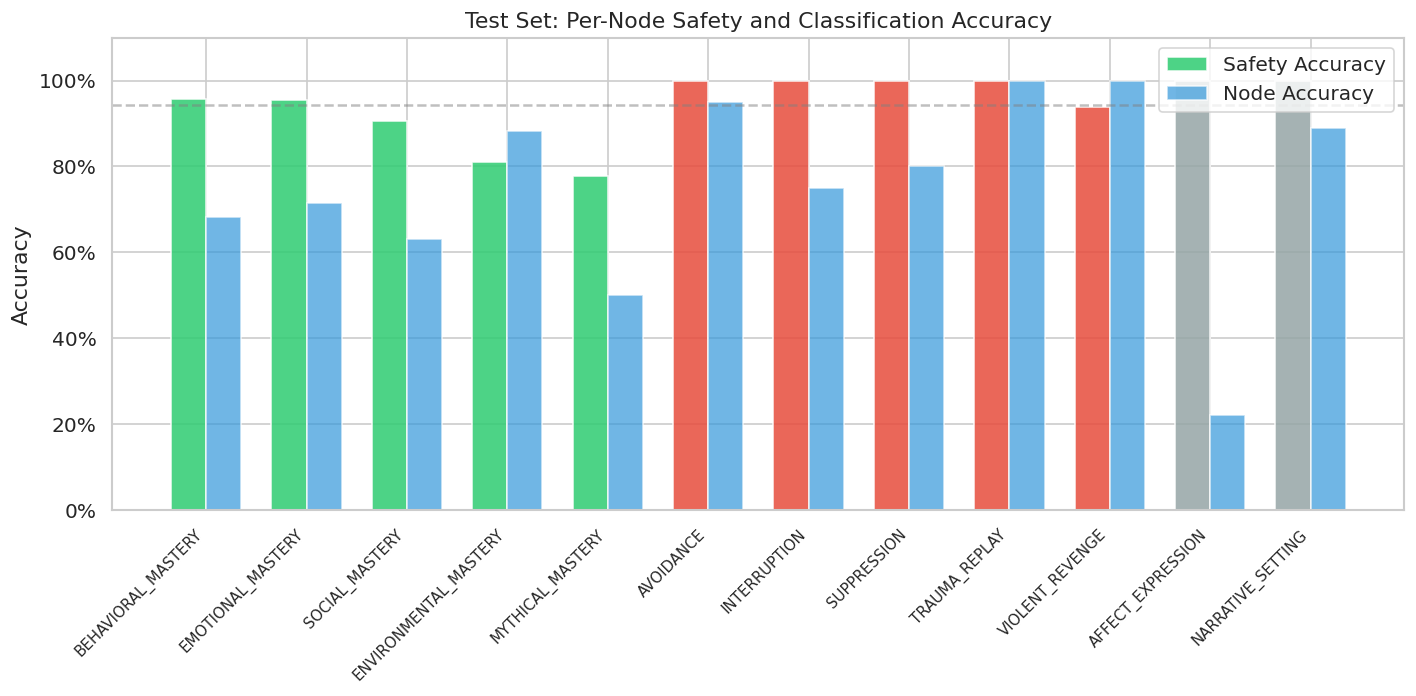

In [6]:
# Visualization: Per-node safety and node accuracy (grouped bar)
fig, ax = plt.subplots(figsize=(12, 6))

# Sort by category then safety
plot_df = node_df.sort_values(["category", "safety_acc"], ascending=[True, False])
x = np.arange(len(plot_df))
width = 0.35

colors_safety = ["#2ecc71" if c == "Adaptive" else "#e74c3c" if c == "Maladaptive" else "#95a5a6"
                 for c in plot_df["category"]]

bars1 = ax.bar(x - width/2, plot_df["safety_acc"], width, label="Safety Accuracy",
               color=colors_safety, alpha=0.85, edgecolor="white")
bars2 = ax.bar(x + width/2, plot_df["node_acc"], width, label="Node Accuracy",
               color="#3498db", alpha=0.7, edgecolor="white")

ax.set_ylabel("Accuracy")
ax.set_title("Test Set: Per-Node Safety and Classification Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["node"], rotation=45, ha="right", fontsize=9)
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend()
ax.axhline(y=test_metrics["safety_accuracy"], color="gray", linestyle="--", alpha=0.5, label="Overall safety")

plt.tight_layout()
plt.savefig("../data/results/test_per_node_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Error listing: False Negatives and False Positives
labeled = test_primary[test_primary["gt_safe"].notna()].copy()

fn_cases = labeled[(labeled["gt_safe"] == False) & (labeled["pred_safe"] == True)]
fp_cases = labeled[(labeled["gt_safe"] == True) & (labeled["pred_safe"] == False)]

print(f"=== FALSE NEGATIVES (unsafe missed — clinically dangerous) ===")
print(f"Count: {len(fn_cases)}\n")
for _, row in fn_cases.iterrows():
    print(f"  {row['test']} (Suite {row['suite_id']}: {row['suite']})")
    print(f"  GT: {row['gt_node']} (unsafe) → Pred: {row['pred_node']} (safe), conf={row['conf']:.3f}")
    print(f"  Input: {row['user_input'][:120]}...")
    print()

print(f"\n=== FALSE POSITIVES (safe flagged — conservative) ===")
print(f"Count: {len(fp_cases)}\n")
for _, row in fp_cases.iterrows():
    print(f"  {row['test']} (Suite {row['suite_id']}: {row['suite']})")
    print(f"  GT: {row['gt_node']} (safe) → Pred: {row['pred_node']} (unsafe), conf={row['conf']:.3f}")
    print()

=== FALSE NEGATIVES (unsafe missed — clinically dangerous) ===
Count: 1

  Crush follower brutally (Suite 2: Lost in an endless, shifting maze with n...)
  GT: VIOLENT_REVENGE (unsafe) → Pred: BEHAVIORAL_MASTERY (safe), conf=0.930
  Input: I trap it between the moving concrete walls and listen while the maze grinds down on it. I stand there and make sure it'...


=== FALSE POSITIVES (safe flagged — conservative) ===
Count: 12

  Guardrail becomes barrier (Suite 1: Car brakes failing while driving toward ...)
  GT: ENVIRONMENTAL_MASTERY (safe) → Pred: TRAUMA_REPLAY (unsafe), conf=0.922

  Grow wings and escape (Suite 1: Car brakes failing while driving toward ...)
  GT: MYTHICAL_MASTERY (safe) → Pred: TRAUMA_REPLAY (unsafe), conf=0.798

  finds people nearby (Suite 2: Lost in an endless, shifting maze with n...)
  GT: SOCIAL_MASTERY (safe) → Pred: TRAUMA_REPLAY (unsafe), conf=0.759

  Wave becomes shallow water (Suite 4: Massive tsunami wave approaching the sho...)
  GT: ENVIRONMENTAL_M

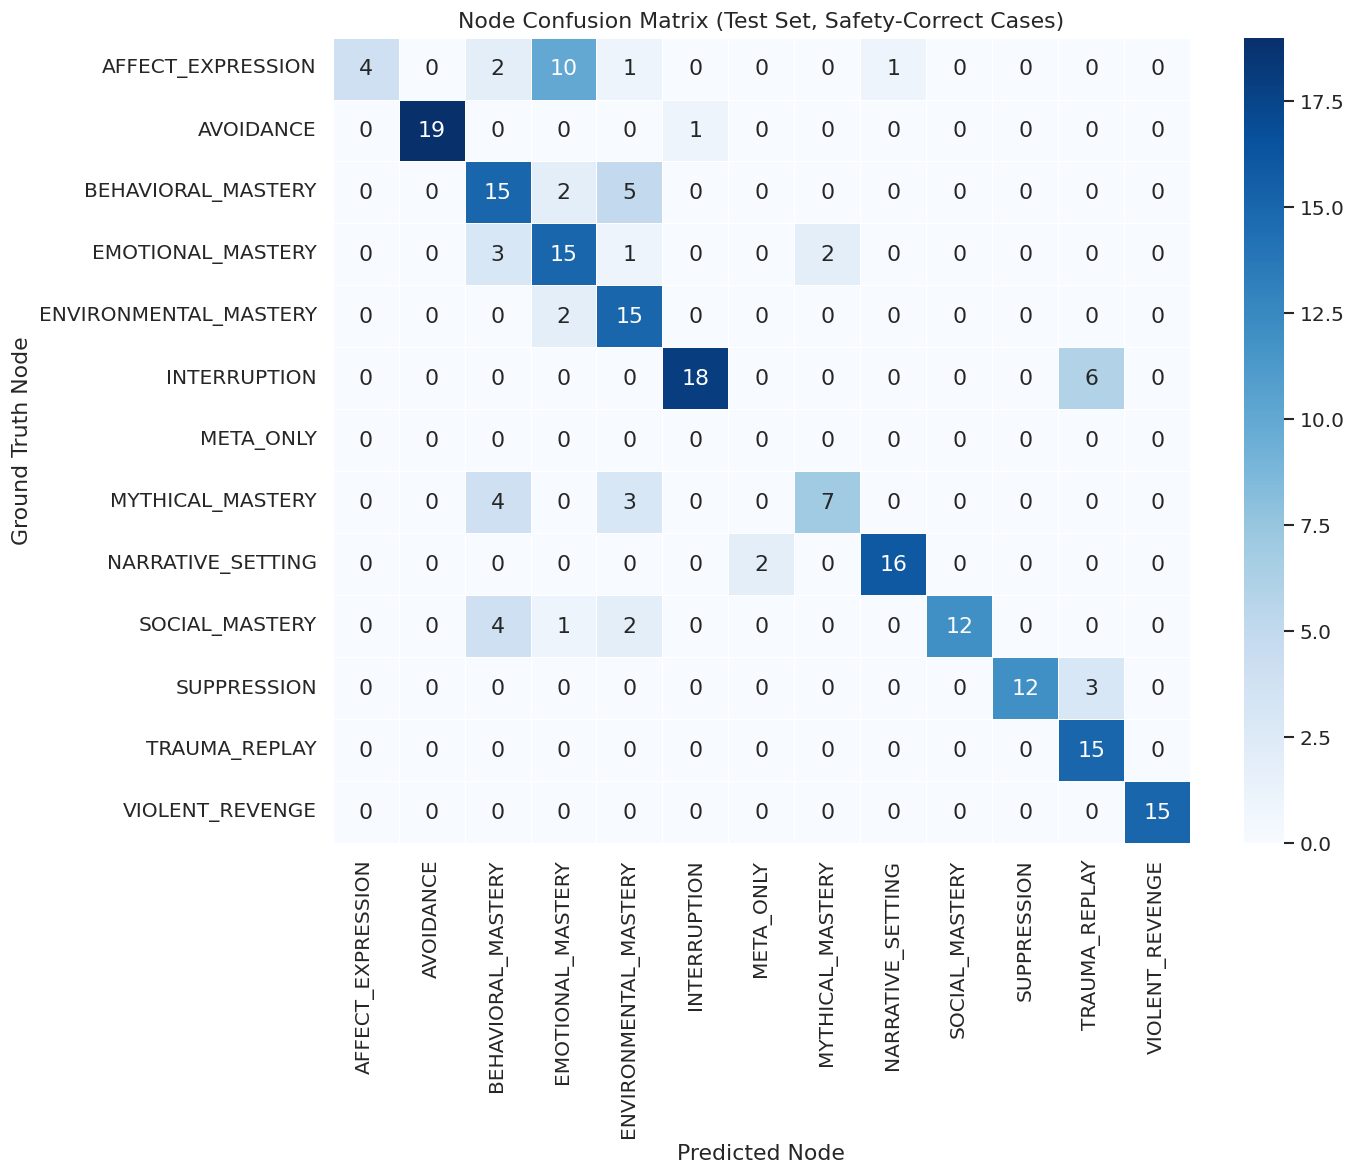


Top Node Confusions (GT → Pred):
  AFFECT_EXPRESSION → EMOTIONAL_MASTERY: 10
  INTERRUPTION → TRAUMA_REPLAY: 6
  BEHAVIORAL_MASTERY → ENVIRONMENTAL_MASTERY: 5
  MYTHICAL_MASTERY → BEHAVIORAL_MASTERY: 4
  SOCIAL_MASTERY → BEHAVIORAL_MASTERY: 4
  EMOTIONAL_MASTERY → BEHAVIORAL_MASTERY: 3
  MYTHICAL_MASTERY → ENVIRONMENTAL_MASTERY: 3
  SUPPRESSION → TRAUMA_REPLAY: 3
  AFFECT_EXPRESSION → BEHAVIORAL_MASTERY: 2
  BEHAVIORAL_MASTERY → EMOTIONAL_MASTERY: 2


In [8]:
# Node confusion matrix (on safety-correct cases)
safety_correct = labeled[labeled["safe_ok"] == True]
all_nodes = sorted(set(safety_correct["gt_node"].unique()) | set(safety_correct["pred_node"].unique()))

conf_matrix = pd.crosstab(
    safety_correct["gt_node"],
    safety_correct["pred_node"],
    margins=False
).reindex(index=all_nodes, columns=all_nodes, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, linecolor="white")
ax.set_title("Node Confusion Matrix (Test Set, Safety-Correct Cases)")
ax.set_ylabel("Ground Truth Node")
ax.set_xlabel("Predicted Node")
plt.tight_layout()
plt.savefig("../data/results/test_node_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Top confusions
print("\nTop Node Confusions (GT → Pred):")
confusions = []
for gt in all_nodes:
    for pred in all_nodes:
        if gt != pred and conf_matrix.loc[gt, pred] > 0:
            confusions.append((gt, pred, conf_matrix.loc[gt, pred]))
confusions.sort(key=lambda x: -x[2])
for gt, pred, count in confusions[:10]:
    print(f"  {gt} → {pred}: {count}")

---
## 2. Boundary Case Analysis

36 boundary cases (6 buried alive excluded) with human annotations from `test_annotation_log.json`.  
These are designed to sit at decision boundaries between two nodes (e.g., proportionate defense vs violent revenge).  
**Annotator:** Ramon Zacharias, assisted by Claude Opus 4.6.

In [9]:
# Match boundary annotations to classifier predictions
boundary_annotations = annotations["boundary_cases"]

# Build lookup from results by input text
results_by_input = {}
for _, row in test_df.iterrows():
    key = row["user_input"][:100].strip()
    results_by_input[key] = row

# Also get boundary type from dataset
boundary_type_lookup = {}
for suite in test_dataset:
    for t in suite["tests"]:
        if t.get("test_type") == "boundary":
            key = t["input"][:100].strip()
            boundary_type_lookup[key] = t.get("boundary", "unknown")

# Match
boundary_matched = []
for bc in boundary_annotations:
    key = bc["input"][:100].strip()
    r = results_by_input.get(key)
    btype = boundary_type_lookup.get(key, "unknown")
    if r is not None:
        boundary_matched.append({
            "description": bc["boundary"],
            "boundary_type": btype,
            "theme": bc["theme"][:40],
            "ramon_safe": bc["ramon_label"]["safe"],
            "ramon_node": bc["ramon_label"]["node"],
            "pred_safe": r["pred_safe"],
            "pred_node": r["pred_node"],
            "conf": r["conf"],
            "input_short": bc["input"][:80],
        })

bdf = pd.DataFrame(boundary_matched)
print(f"Boundary cases matched: {len(bdf)}/{len(boundary_annotations)}")

# Compute metrics
bdf["safety_ok"] = bdf["ramon_safe"] == bdf["pred_safe"]
bdf["node_ok"] = (bdf["ramon_safe"] == bdf["pred_safe"]) & (bdf["ramon_node"] == bdf["pred_node"])
bdf["is_fn"] = (~bdf["ramon_safe"]) & (bdf["pred_safe"])
bdf["is_fp"] = (bdf["ramon_safe"]) & (~bdf["pred_safe"])

n_b = len(bdf)
safe_ok = bdf["safety_ok"].sum()
node_ok = bdf.loc[bdf["safety_ok"], "node_ok"].sum()
n_fn = bdf["is_fn"].sum()
n_fp = bdf["is_fp"].sum()
tp_b = ((~bdf["ramon_safe"]) & (~bdf["pred_safe"])).sum()
tn_b = ((bdf["ramon_safe"]) & (bdf["pred_safe"])).sum()

recall_b = tp_b / (tp_b + n_fn) if (tp_b + n_fn) > 0 else 0
precision_b = tp_b / (tp_b + n_fp) if (tp_b + n_fp) > 0 else 0
f1_b = 2 * precision_b * recall_b / (precision_b + recall_b) if (precision_b + recall_b) > 0 else 0

print(f"\n=== Boundary Case Metrics (vs Human Annotation) ===")
print(f"Safety Accuracy: {safe_ok}/{n_b} ({safe_ok/n_b:.1%})")
print(f"Node Accuracy:   {node_ok}/{bdf['safety_ok'].sum()} ({node_ok/bdf['safety_ok'].sum():.1%}) (safety-correct only)")
print(f"Unsafe Recall:   {recall_b:.1%} ({n_fn} FN)")
print(f"Unsafe Precision:{precision_b:.1%} ({n_fp} FP)")
print(f"Unsafe F1:       {f1_b:.3f}")
print(f"\nTP: {tp_b}, TN: {tn_b}, FP: {n_fp}, FN: {n_fn}")

Boundary cases matched: 35/36

=== Boundary Case Metrics (vs Human Annotation) ===
Safety Accuracy: 29/35 (82.9%)
Node Accuracy:   25/29 (86.2%) (safety-correct only)
Unsafe Recall:   91.7% (2 FN)
Unsafe Precision:84.6% (4 FP)
Unsafe F1:       0.880

TP: 22, TN: 7, FP: 4, FN: 2


In [10]:
# Per boundary type breakdown
btype_order = ["description_vs_replay", "regulation_vs_denial", "passivity",
               "action_vs_escape", "proportionality", "active_vs_passive"]

btype_rows = []
for btype in btype_order:
    subset = bdf[bdf["boundary_type"] == btype]
    if len(subset) == 0:
        continue
    n = len(subset)
    sok = subset["safety_ok"].sum()
    fn = subset["is_fn"].sum()
    fp = subset["is_fp"].sum()
    ramon_unsafe = (~subset["ramon_safe"]).sum()
    ramon_safe = subset["ramon_safe"].sum()
    btype_rows.append({
        "Boundary": btype,
        "N": n,
        "Human: safe": ramon_safe,
        "Human: unsafe": ramon_unsafe,
        "Safety Acc": f"{sok}/{n} ({sok/n:.0%})",
        "FN": fn,
        "FP": fp,
    })

btype_df = pd.DataFrame(btype_rows)
display(btype_df)

# List FN cases
fn_boundary = bdf[bdf["is_fn"]]
if len(fn_boundary) > 0:
    print("\n=== False Negatives (unsafe missed) ===")
    for _, row in fn_boundary.iterrows():
        print(f"  {row['description']} ({row['boundary_type']})")
        print(f"  GT: {row['ramon_node']} (unsafe) → Pred: {row['pred_node']} (safe), conf={row['conf']:.3f}")
        print(f"  '{row['input_short']}...'")
        print()

,Boundary,N,Human: safe,Human: unsafe,Safety Acc,FN,FP
0,description_vs_replay,6,0,6,6/6 (100%),0,0
1,regulation_vs_denial,6,0,6,6/6 (100%),0,0
2,passivity,6,0,6,6/6 (100%),0,0
3,action_vs_escape,5,0,5,4/5 (80%),1,0
4,proportionality,6,6,0,4/6 (67%),0,2
5,active_vs_passive,6,5,1,3/6 (50%),1,2



=== False Negatives (unsafe missed) ===
  Run for an opening (active_vs_passive)
  GT: AVOIDANCE (unsafe) → Pred: ENVIRONMENTAL_MASTERY (safe), conf=0.877
  'Instead of pounding on the wall, I just take off down the nearest passage as fas...'

  Refusing the drop (action_vs_escape)
  GT: INTERRUPTION (unsafe) → Pred: EMOTIONAL_MASTERY (safe), conf=0.820
  'I tell myself this isn't how it ends and try to make the elevator stop falling b...'



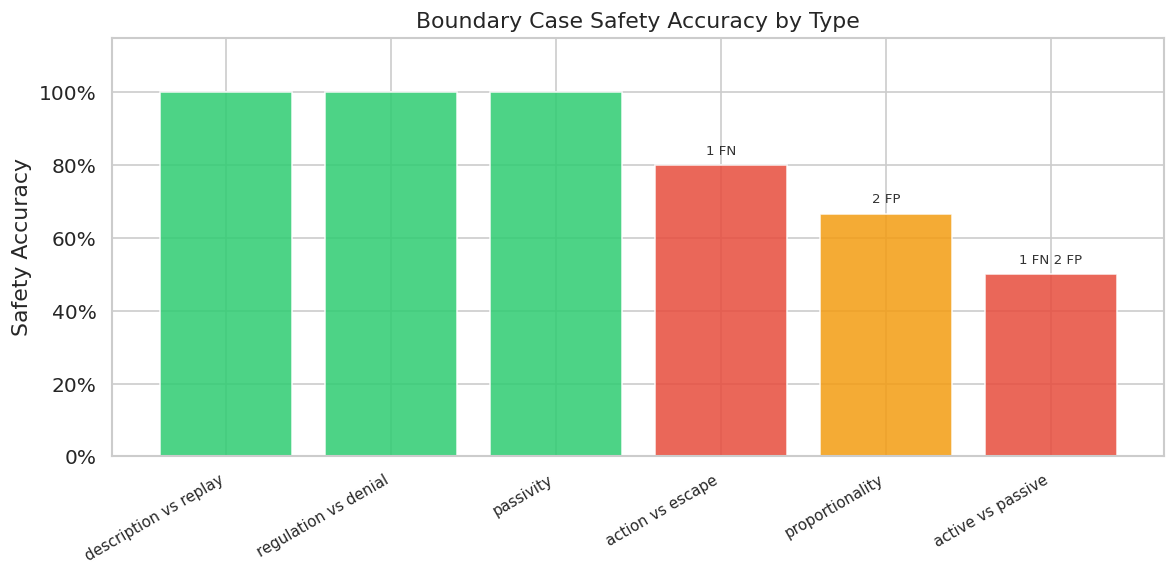

In [11]:
# Visualization: Boundary type performance
fig, ax = plt.subplots(figsize=(10, 5))

btypes = [r["Boundary"] for r in btype_rows]
safety_accs = [bdf[bdf["boundary_type"] == bt]["safety_ok"].mean() for bt in btypes]
fn_counts = [bdf[bdf["boundary_type"] == bt]["is_fn"].sum() for bt in btypes]
fp_counts = [bdf[bdf["boundary_type"] == bt]["is_fp"].sum() for bt in btypes]

x = np.arange(len(btypes))
colors = ["#e74c3c" if fn > 0 else "#f39c12" if fp > 0 else "#2ecc71" for fn, fp in zip(fn_counts, fp_counts)]

bars = ax.bar(x, safety_accs, color=colors, edgecolor="white", alpha=0.85)
ax.set_ylabel("Safety Accuracy")
ax.set_title("Boundary Case Safety Accuracy by Type")
ax.set_xticks(x)
ax.set_xticklabels([b.replace("_", " ") for b in btypes], rotation=30, ha="right", fontsize=9)
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

# Annotate with FN/FP counts
for i, (fn, fp) in enumerate(zip(fn_counts, fp_counts)):
    label = ""
    if fn > 0: label += f"{fn} FN "
    if fp > 0: label += f"{fp} FP"
    if label:
        ax.text(i, safety_accs[i] + 0.03, label.strip(), ha="center", fontsize=8, color="#333")

plt.tight_layout()
plt.savefig("../data/results/boundary_safety_by_type.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 3. System 1 vs System 2 Comparison

**Dev set (420 labeled cases).** S1 = direct label-engineered classification; S2 = Chain-of-Thought structured reasoning.  
Reference: `docs/planning/System2_CoT_Findings.md`

In [12]:
# Compute metrics for both systems on dev set
dev_s1_clean = dev_s1[dev_s1["gt_safe"].notna() & dev_s1["gt_node"].notna()]
dev_s2_clean = dev_s2[dev_s2["gt_safe"].notna() & dev_s2["gt_node"].notna()]

m_s1 = compute_safety_metrics(dev_s1_clean)
m_s2 = compute_safety_metrics(dev_s2_clean)

comp_s1s2 = pd.DataFrame({
    "Metric": ["N", "Safety Accuracy", "Unsafe Recall", "Unsafe Precision", "Unsafe F1",
               "Node Accuracy", "False Positives", "False Negatives", "Mean Confidence"],
    "S1 (Direct)": [
        m_s1["n"], f"{m_s1['safety_accuracy']:.1%}", f"{m_s1['unsafe_recall']:.1%}",
        f"{m_s1['unsafe_precision']:.1%}", f"{m_s1['unsafe_f1']:.3f}",
        f"{m_s1['node_accuracy']:.1%}", m_s1["fp"], m_s1["fn"], f"{m_s1['mean_confidence']:.3f}",
    ],
    "S2 (CoT)": [
        m_s2["n"], f"{m_s2['safety_accuracy']:.1%}", f"{m_s2['unsafe_recall']:.1%}",
        f"{m_s2['unsafe_precision']:.1%}", f"{m_s2['unsafe_f1']:.3f}",
        f"{m_s2['node_accuracy']:.1%}", m_s2["fp"], m_s2["fn"], f"{m_s2['mean_confidence']:.3f}",
    ],
    "Delta": [
        "",
        f"{(m_s2['safety_accuracy']-m_s1['safety_accuracy'])*100:+.1f} pp",
        f"{(m_s2['unsafe_recall']-m_s1['unsafe_recall'])*100:+.1f} pp",
        f"{(m_s2['unsafe_precision']-m_s1['unsafe_precision'])*100:+.1f} pp",
        f"{m_s2['unsafe_f1']-m_s1['unsafe_f1']:+.3f}",
        f"{(m_s2['node_accuracy']-m_s1['node_accuracy'])*100:+.1f} pp",
        f"{m_s2['fp']-m_s1['fp']:+d}",
        f"{m_s2['fn']-m_s1['fn']:+d}",
        f"{m_s2['mean_confidence']-m_s1['mean_confidence']:+.3f}",
    ],
})

print("System 1 vs System 2 — Dev Set")
print("=" * 60)
display(comp_s1s2)

System 1 vs System 2 — Dev Set


,Metric,S1 (Direct),S2 (CoT),Delta
0,N,420,420,
1,Safety Accuracy,93.8%,94.5%,+0.7 pp
2,Unsafe Recall,98.9%,98.9%,+0.0 pp
3,Unsafe Precision,88.1%,89.4%,+1.3 pp
4,Unsafe F1,0.932,0.939,+0.007
5,Node Accuracy,74.9%,82.6%,+7.7 pp
6,False Positives,24,21,-3
7,False Negatives,2,2,+0
8,Mean Confidence,0.964,0.799,-0.165


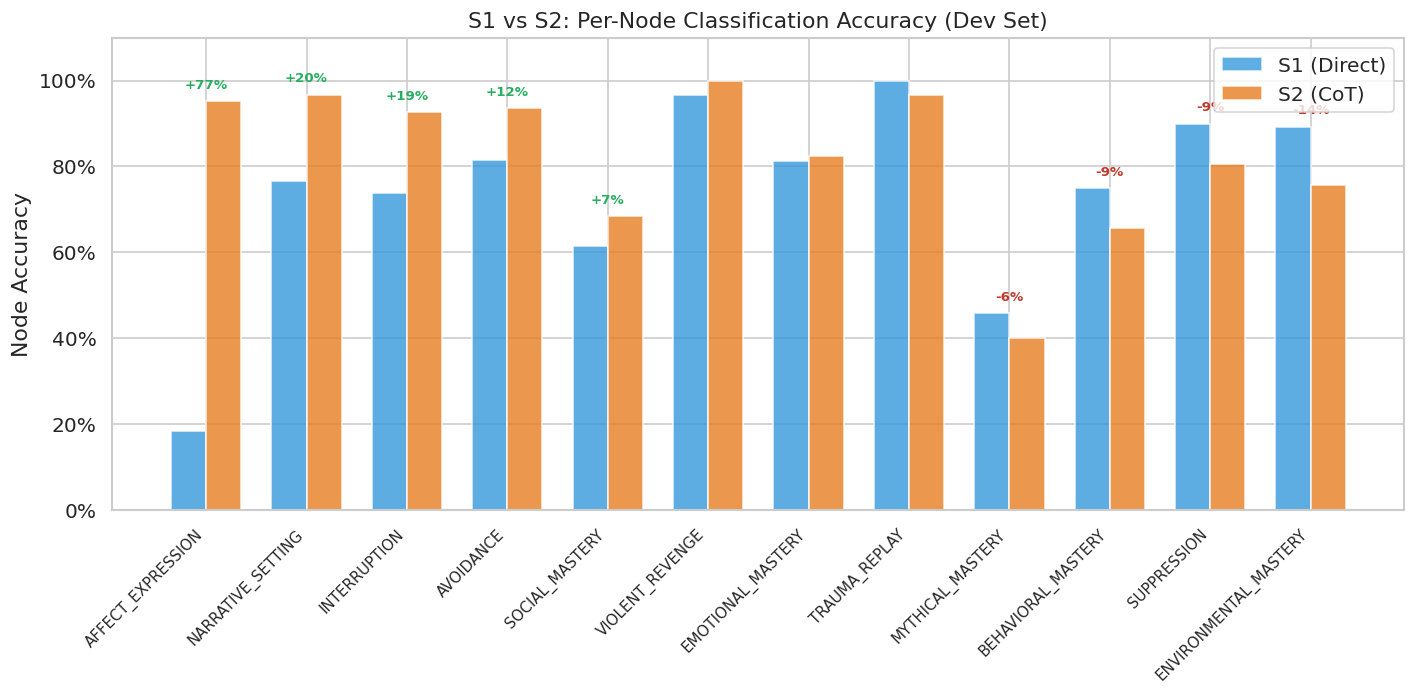

In [13]:
# Per-node comparison: S1 vs S2
nodes_s1 = per_node_breakdown(dev_s1_clean).set_index("node")
nodes_s2 = per_node_breakdown(dev_s2_clean).set_index("node")

all_nodes_list = sorted(set(nodes_s1.index) | set(nodes_s2.index))

node_comp_rows = []
for node in all_nodes_list:
    s1_nacc = nodes_s1.loc[node, "node_acc"] if node in nodes_s1.index else 0
    s2_nacc = nodes_s2.loc[node, "node_acc"] if node in nodes_s2.index else 0
    delta = s2_nacc - s1_nacc
    node_comp_rows.append({
        "Node": node,
        "S1 Node Acc": s1_nacc,
        "S2 Node Acc": s2_nacc,
        "Delta": delta,
    })

node_comp = pd.DataFrame(node_comp_rows).sort_values("Delta", ascending=False)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(node_comp))
width = 0.35

ax.bar(x - width/2, node_comp["S1 Node Acc"], width, label="S1 (Direct)", color="#3498db", alpha=0.8)
ax.bar(x + width/2, node_comp["S2 Node Acc"], width, label="S2 (CoT)", color="#e67e22", alpha=0.8)

ax.set_ylabel("Node Accuracy")
ax.set_title("S1 vs S2: Per-Node Classification Accuracy (Dev Set)")
ax.set_xticks(x)
ax.set_xticklabels(node_comp["Node"], rotation=45, ha="right", fontsize=9)
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend()

# Annotate deltas
for i, row in enumerate(node_comp.itertuples()):
    if abs(row.Delta) > 0.05:
        color = "#27ae60" if row.Delta > 0 else "#c0392b"
        ax.text(i, max(row._2, row._3) + 0.03, f"{row.Delta:+.0%}",
                ha="center", fontsize=8, color=color, fontweight="bold")

plt.tight_layout()
plt.savefig("../data/results/s1_vs_s2_node_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# Disagreement analysis: cases where S1 and S2 gave different safety verdicts
# Merge on user_input
merged = dev_s1_clean[["user_input", "gt_safe", "gt_node", "pred_safe", "pred_node", "safe_ok", "conf", "test"]].copy()
merged.columns = ["user_input", "gt_safe", "gt_node", "s1_pred_safe", "s1_pred_node", "s1_safe_ok", "s1_conf", "test"]

s2_cols = dev_s2_clean[["user_input", "pred_safe", "pred_node", "safe_ok", "conf"]].copy()
s2_cols.columns = ["user_input", "s2_pred_safe", "s2_pred_node", "s2_safe_ok", "s2_conf"]

merged = merged.merge(s2_cols, on="user_input", how="inner")

# Safety disagreements
disagree = merged[merged["s1_safe_ok"] != merged["s2_safe_ok"]]
s2_fixed = disagree[(disagree["s1_safe_ok"] == False) & (disagree["s2_safe_ok"] == True)]
s2_broke = disagree[(disagree["s1_safe_ok"] == True) & (disagree["s2_safe_ok"] == False)]

print(f"Safety disagreements: {len(disagree)} cases")
print(f"  S2 fixed (S1 wrong → S2 right): {len(s2_fixed)}")
print(f"  S2 broke (S1 right → S2 wrong): {len(s2_broke)}")
print(f"  Net: S2 {'gains' if len(s2_fixed) > len(s2_broke) else 'loses'} {abs(len(s2_fixed)-len(s2_broke))} cases")

Safety disagreements: 0 cases
  S2 fixed (S1 wrong → S2 right): 0
  S2 broke (S1 right → S2 wrong): 0
  Net: S2 loses 0 cases


---
## 4. Uncertainty Quantification: 2×2 Analysis

**Research question:** Which UQ method better predicts classifier errors?  
**Design:** 2 classifiers (S1, S2) × 2 UQ methods (logprobs, semantic consistency)  
**Key metric:** Separation = mean agreement (correct) − mean agreement (errors). Larger = better at distinguishing.

In [15]:
# Logprobs confidence separation (from dev benchmark CSVs)
def logprobs_separation(df):
    labeled = df[df["gt_safe"].notna() & df["gt_node"].notna()].copy()
    correct = labeled[labeled["safe_ok"] == True]["conf"]
    errors = labeled[labeled["safe_ok"] == False]["conf"]
    return {
        "correct_mean": correct.mean(),
        "error_mean": errors.mean(),
        "separation": correct.mean() - errors.mean(),
        "n_correct": len(correct),
        "n_errors": len(errors),
    }

s1_lp = logprobs_separation(dev_s1_clean)
s2_lp = logprobs_separation(dev_s2_clean)

# Semantic consistency separation (from consistency CSV)
def consistency_separation(cdf, system_prefix):
    errors = cdf[cdf["system"] == f"{system_prefix}_error"]["agreement"]
    correct = cdf[cdf["system"] == f"{system_prefix}_correct"]["agreement"]
    return {
        "correct_mean": correct.mean(),
        "error_mean": errors.mean(),
        "separation": correct.mean() - errors.mean(),
        "n_correct": len(correct),
        "n_errors": len(errors),
    }

s1_sc = consistency_separation(consistency_df, "S1")
s2_sc = consistency_separation(consistency_df, "S2")

# 2x2 table
uq_table = pd.DataFrame({
    "UQ Method": ["Logprobs", "Logprobs", "Semantic Consistency", "Semantic Consistency"],
    "Classifier": ["S1", "S2", "S1", "S2"],
    "Correct Mean": [s1_lp["correct_mean"], s2_lp["correct_mean"], s1_sc["correct_mean"], s2_sc["correct_mean"]],
    "Error Mean": [s1_lp["error_mean"], s2_lp["error_mean"], s1_sc["error_mean"], s2_sc["error_mean"]],
    "Separation": [s1_lp["separation"], s2_lp["separation"], s1_sc["separation"], s2_sc["separation"]],
    "N Errors": [s1_lp["n_errors"], s2_lp["n_errors"], s1_sc["n_errors"], s2_sc["n_errors"]],
    "N Correct": [s1_lp["n_correct"], s2_lp["n_correct"], s1_sc["n_correct"], s2_sc["n_correct"]],
})

display(uq_table.round(3))


,UQ Method,Classifier,Correct Mean,Error Mean,Separation,N Errors,N Correct
0,Logprobs,S1,0.968,0.909,0.059,26,394
1,Logprobs,S2,0.800,0.788,0.012,23,397
2,Semantic Consistency,S1,0.968,0.923,0.045,26,25
3,Semantic Consistency,S2,0.936,0.861,0.075,23,25


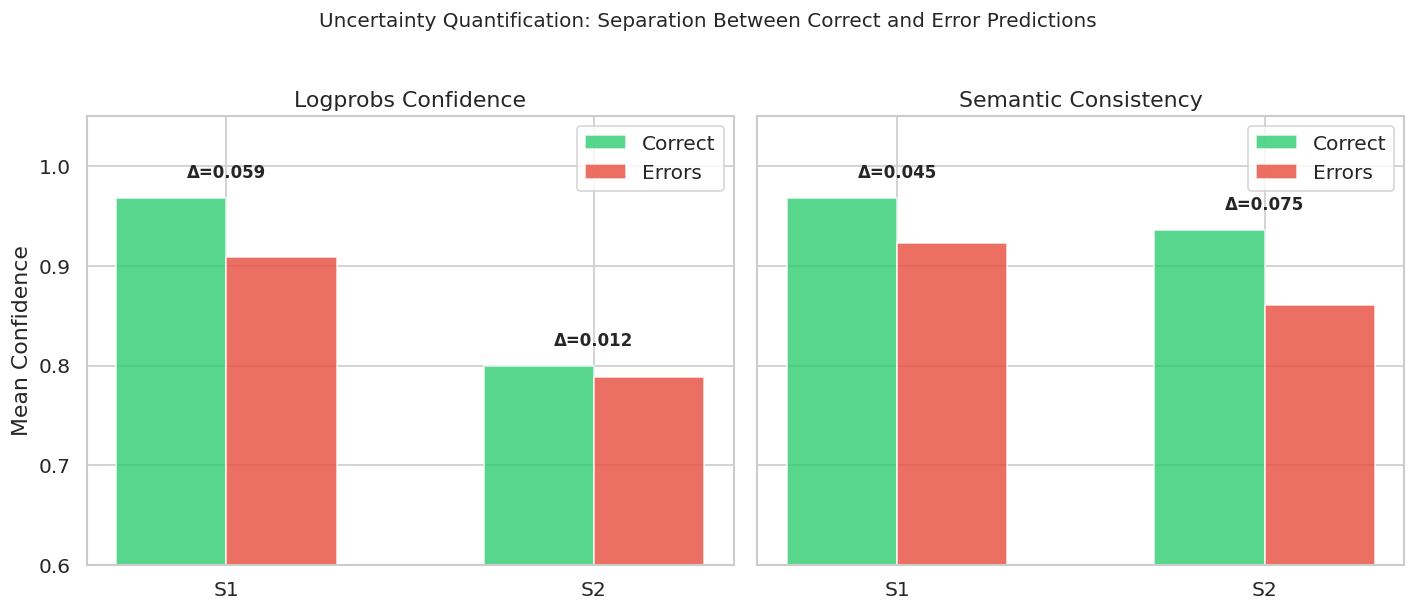

In [16]:
# Visualization: 2x2 separation comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Left: Logprobs
ax = axes[0]
x = [0, 1]
correct_vals = [s1_lp["correct_mean"], s2_lp["correct_mean"]]
error_vals = [s1_lp["error_mean"], s2_lp["error_mean"]]
ax.bar([p - 0.15 for p in x], correct_vals, 0.3, label="Correct", color="#2ecc71", alpha=0.8)
ax.bar([p + 0.15 for p in x], error_vals, 0.3, label="Errors", color="#e74c3c", alpha=0.8)
for i in range(2):
    sep = correct_vals[i] - error_vals[i]
    ax.annotate(f"Δ={sep:.3f}", xy=(i, max(correct_vals[i], error_vals[i]) + 0.02),
                ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(["S1", "S2"])
ax.set_ylabel("Mean Confidence")
ax.set_title("Logprobs Confidence")
ax.set_ylim(0.6, 1.05)
ax.legend()

# Right: Semantic Consistency
ax = axes[1]
correct_vals = [s1_sc["correct_mean"], s2_sc["correct_mean"]]
error_vals = [s1_sc["error_mean"], s2_sc["error_mean"]]
ax.bar([p - 0.15 for p in x], correct_vals, 0.3, label="Correct", color="#2ecc71", alpha=0.8)
ax.bar([p + 0.15 for p in x], error_vals, 0.3, label="Errors", color="#e74c3c", alpha=0.8)
for i in range(2):
    sep = correct_vals[i] - error_vals[i]
    ax.annotate(f"Δ={sep:.3f}", xy=(i, max(correct_vals[i], error_vals[i]) + 0.02),
                ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(["S1", "S2"])
ax.set_title("Semantic Consistency")
ax.legend()

fig.suptitle("Uncertainty Quantification: Separation Between Correct and Error Predictions", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("../data/results/uq_2x2_separation.png", dpi=150, bbox_inches="tight")
plt.show()

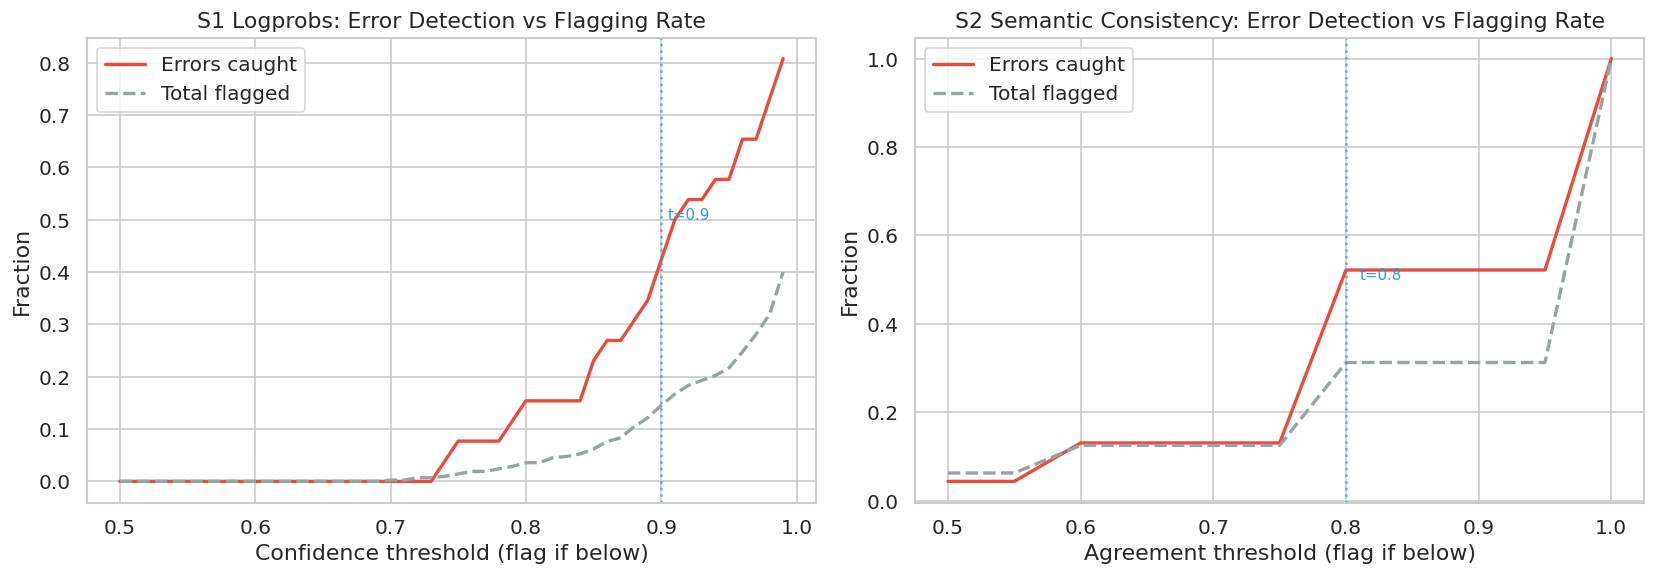

In [17]:
# Threshold analysis: what fraction of errors would be caught at each threshold?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# S1: logprobs thresholding
ax = axes[0]
thresholds = np.arange(0.5, 1.0, 0.01)
s1_labeled = dev_s1_clean[dev_s1_clean["gt_safe"].notna()].copy()
s1_errors_conf = s1_labeled[s1_labeled["safe_ok"] == False]["conf"].values
s1_all_conf = s1_labeled["conf"].values
n_s1_errors = len(s1_errors_conf)
n_s1_total = len(s1_all_conf)

errors_caught = [np.sum(s1_errors_conf < t) / n_s1_errors for t in thresholds]
total_flagged = [np.sum(s1_all_conf < t) / n_s1_total for t in thresholds]

ax.plot(thresholds, errors_caught, label="Errors caught", color="#e74c3c", linewidth=2)
ax.plot(thresholds, total_flagged, label="Total flagged", color="#95a5a6", linewidth=2, linestyle="--")
ax.set_xlabel("Confidence threshold (flag if below)")
ax.set_ylabel("Fraction")
ax.set_title("S1 Logprobs: Error Detection vs Flagging Rate")
ax.legend()
ax.axvline(x=0.9, color="#3498db", linestyle=":", alpha=0.7)
ax.text(0.905, 0.5, "t=0.9", fontsize=9, color="#3498db")

# S2: consistency thresholding  
ax = axes[1]
agree_thresholds = np.arange(0.5, 1.01, 0.05)
s2_errors_agree = consistency_df[consistency_df["system"] == "S2_error"]["agreement"].values
s2_correct_agree = consistency_df[consistency_df["system"] == "S2_correct"]["agreement"].values
s2_all_agree = np.concatenate([s2_errors_agree, s2_correct_agree])
n_s2_errors = len(s2_errors_agree)
n_s2_total = len(s2_all_agree)

errors_caught_sc = [np.sum(s2_errors_agree < t) / n_s2_errors for t in agree_thresholds]
total_flagged_sc = [np.sum(s2_all_agree < t) / n_s2_total for t in agree_thresholds]

ax.plot(agree_thresholds, errors_caught_sc, label="Errors caught", color="#e74c3c", linewidth=2)
ax.plot(agree_thresholds, total_flagged_sc, label="Total flagged", color="#95a5a6", linewidth=2, linestyle="--")
ax.set_xlabel("Agreement threshold (flag if below)")
ax.set_ylabel("Fraction")
ax.set_title("S2 Semantic Consistency: Error Detection vs Flagging Rate")
ax.legend()
ax.axvline(x=0.8, color="#3498db", linestyle=":", alpha=0.7)
ax.text(0.81, 0.5, "t=0.8", fontsize=9, color="#3498db")

plt.tight_layout()
plt.savefig("../data/results/uq_threshold_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# Practical threshold comparison table
s1_labeled = dev_s1_clean[dev_s1_clean["gt_safe"].notna()].copy()
s1_err = s1_labeled[s1_labeled["safe_ok"] == False]
s1_all = s1_labeled

# S1 logprobs at threshold 0.9
s1_lp_flagged = (s1_all["conf"] < 0.9).sum()
s1_lp_errors_caught = (s1_err["conf"] < 0.9).sum()

# S1 consistency at threshold 0.8
s1_sc_err = consistency_df[consistency_df["system"] == "S1_error"]
s1_sc_cor = consistency_df[consistency_df["system"] == "S1_correct"]
s1_sc_flagged_err = (s1_sc_err["agreement"] < 0.8).sum()
s1_sc_flagged_cor = (s1_sc_cor["agreement"] < 0.8).sum()

# S2 consistency at threshold 0.8
s2_sc_err = consistency_df[consistency_df["system"] == "S2_error"]
s2_sc_cor = consistency_df[consistency_df["system"] == "S2_correct"]
s2_sc_flagged_err = (s2_sc_err["agreement"] < 0.8).sum()
s2_sc_flagged_cor = (s2_sc_cor["agreement"] < 0.8).sum()

practical = pd.DataFrame([
    {"Method": "S1 Logprobs (t<0.9)", "Separation": f"{s1_lp['separation']:.3f}",
     "Errors Flagged": f"{s1_lp_errors_caught}/{len(s1_err)} ({s1_lp_errors_caught/len(s1_err):.0%})",
     "Total Flagged": f"{s1_lp_flagged}/{len(s1_all)} ({s1_lp_flagged/len(s1_all):.0%})"},
    {"Method": "S1 Consistency (a<0.8)", "Separation": f"{s1_sc['separation']:.3f}",
     "Errors Flagged": f"{s1_sc_flagged_err}/{len(s1_sc_err)} ({s1_sc_flagged_err/len(s1_sc_err):.0%})",
     "Total Flagged": f"{s1_sc_flagged_err+s1_sc_flagged_cor}/{len(s1_sc_err)+len(s1_sc_cor)} ({(s1_sc_flagged_err+s1_sc_flagged_cor)/(len(s1_sc_err)+len(s1_sc_cor)):.0%})"},
    {"Method": "S2 Logprobs (t<0.9)", "Separation": f"{s2_lp['separation']:.3f}",
     "Errors Flagged": "~100%*",
     "Total Flagged": "~96%*"},
    {"Method": "S2 Consistency (a<0.8)", "Separation": f"{s2_sc['separation']:.3f}",
     "Errors Flagged": f"{s2_sc_flagged_err}/{len(s2_sc_err)} ({s2_sc_flagged_err/len(s2_sc_err):.0%})",
     "Total Flagged": f"{s2_sc_flagged_err+s2_sc_flagged_cor}/{len(s2_sc_err)+len(s2_sc_cor)} ({(s2_sc_flagged_err+s2_sc_flagged_cor)/(len(s2_sc_err)+len(s2_sc_cor)):.0%})"},
])

print("Practical Threshold Comparison")
print("*S2 logprobs flags ~96% of ALL cases at t<0.9, making it unusable.")
display(practical)

Practical Threshold Comparison
*S2 logprobs flags ~96% of ALL cases at t<0.9, making it unusable.


,Method,Separation,Errors Flagged,Total Flagged
0,S1 Logprobs (t<0.9),0.059,11/26 (42%),61/420 (15%)
1,S1 Consistency (a<0.8),0.045,3/26 (12%),3/51 (6%)
2,S2 Logprobs (t<0.9),0.012,~100%*,~96%*
3,S2 Consistency (a<0.8),0.075,3/23 (13%),6/48 (12%)


---
## 5. Summary & Conclusions

In [19]:
print("="*70)
print("EVALUATION SUMMARY")
print("="*70)

print(f"""
1. TEST SET PERFORMANCE (S1, n={test_metrics['n']})
   Safety Accuracy: {test_metrics['safety_accuracy']:.1%}
   Unsafe Recall:   {test_metrics['unsafe_recall']:.1%} ({test_metrics['fn']} FN)
   Unsafe F1:       {test_metrics['unsafe_f1']:.3f}
   Node Accuracy:   {test_metrics['node_accuracy']:.1%}
   → Generalizes well: meets/exceeds dev baseline on all metrics

2. BOUNDARY CASES (n={len(bdf)}, vs human annotation)
   Safety Accuracy: {safe_ok/n_b:.1%}
   False Negatives: {n_fn} (clinically dangerous)
   False Positives: {n_fp} (conservative)
   → {n_fn} unsafe cases missed on genuinely ambiguous inputs

3. COMBINED FALSE NEGATIVES (primary + boundary)
   Total: {test_metrics['fn'] + n_fn} / {test_metrics['n'] + n_b} unsafe cases missed
   Combined Unsafe Recall: {(tp_b + test_metrics['tp']) / (tp_b + test_metrics['tp'] + n_fn + test_metrics['fn']):.1%}

4. S1 vs S2 (dev set, n={m_s1['n']})
   S1: {m_s1['safety_accuracy']:.1%} safety, {m_s1['unsafe_recall']:.1%} recall, {m_s1['fn']} FN
   S2: {m_s2['safety_accuracy']:.1%} safety, {m_s2['unsafe_recall']:.1%} recall, {m_s2['fn']} FN
   → S2 trades recall for marginal accuracy; not justified for safety-critical use

5. UNCERTAINTY QUANTIFICATION (2×2)
   S1 Logprobs separation:       {s1_lp['separation']:.3f}
   S1 Consistency separation:     {s1_sc['separation']:.3f}
   S2 Logprobs separation:        {s2_lp['separation']:.3f}
   S2 Consistency separation:     {s2_sc['separation']:.3f}
   → Neither method reliably predicts errors at clinically useful thresholds
   → Each classifier has a 'matching' UQ method (S1+logprobs, S2+consistency)
   → Reinforces need for therapist-in-the-loop, not automated uncertainty gating
""")

EVALUATION SUMMARY

1. TEST SET PERFORMANCE (S1, n=231)
   Safety Accuracy: 94.4%
   Unsafe Recall:   98.9% (1 FN)
   Unsafe F1:       0.932
   Node Accuracy:   74.8%
   → Generalizes well: meets/exceeds dev baseline on all metrics

2. BOUNDARY CASES (n=35, vs human annotation)
   Safety Accuracy: 82.9%
   False Negatives: 2 (clinically dangerous)
   False Positives: 4 (conservative)
   → 2 unsafe cases missed on genuinely ambiguous inputs

3. COMBINED FALSE NEGATIVES (primary + boundary)
   Total: 3 / 266 unsafe cases missed
   Combined Unsafe Recall: 97.4%

4. S1 vs S2 (dev set, n=420)
   S1: 93.8% safety, 98.9% recall, 2 FN
   S2: 94.5% safety, 98.9% recall, 2 FN
   → S2 trades recall for marginal accuracy; not justified for safety-critical use

5. UNCERTAINTY QUANTIFICATION (2×2)
   S1 Logprobs separation:       0.059
   S1 Consistency separation:     0.045
   S2 Logprobs separation:        0.012
   S2 Consistency separation:     0.075
   → Neither method reliably predicts errors a